# Chapitre 10 - Cours 1 : traitement par lots avec les outils Unix

Les chapitres précédents parlaient de requêtes et de réponses : un client demande, le
système répond le plus vite possible. Le traitement **par lots** (*batch processing*)
change de point de vue : un job lit un gros volume de données d'entrée, calcule pendant
des minutes ou des heures, et écrit une sortie entièrement **dérivée** de son entrée. Ce
premier cours en pose l'intuition sur une seule machine, avec le plus ancien des
frameworks de traitement par lots : le shell Unix. Il couvre l'introduction du chapitre et
la section *Batch Processing with Unix Tools* (*Simple Log Analysis*, *Chain of commands versus custom program*, *Sorting versus in-memory aggregation*, *The Unix Philosophy*).

**Plan.**

1. Trois façons de traiter des données : en ligne, par lots, en flux.
2. Une analyse de journal avec `awk`, `sort`, `uniq` et `head`.
3. Chaîne de commandes contre programme : même résultat, exécution différente.
4. Trier ou agréger en mémoire : l'ensemble de travail et le tri externe.
5. Les tuyaux, un tampon borné et la contre-pression.
6. La philosophie Unix : interface uniforme, logique séparée du câblage, expérimentation.

**Contexte : la troisième partie du livre.** Ce chapitre ouvre la partie III, *Derived
Data*. Son introduction distingue deux familles de systèmes de données. Un **système de
référence** (*system of record*, la « source de vérité ») détient la version faisant foi
de chaque donnée : quand une information y entre, elle y est écrite une fois, et en cas
de désaccord c'est lui qui a raison. Un système de **données dérivées** contient le
résultat d'une transformation de données venues d'ailleurs : cache, index, vue
matérialisée, modèle de recommandation. Une donnée dérivée est redondante (on pourrait
la recalculer depuis la source) mais elle rend les lectures rapides. Le traitement par
lots est l'outil type pour construire de telles données dérivées.

In [1]:
import os
import shutil
import subprocess
import tempfile
import time
import tracemalloc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import batch as B
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
WORK = tempfile.mkdtemp(prefix="ddia_ch10_")      # dossier de travail, effacé en fin de notebook
ENV_C = dict(os.environ, LC_ALL="C")                  # tri octet par octet : rapide et déterministe


def sh(cmd):
    """Lance une commande shell et renvoie sa sortie standard."""
    return subprocess.run(cmd, shell=True, check=True, capture_output=True, text=True, env=ENV_C).stdout

## 1. Trois façons de traiter des données (introduction du chapitre)

Le livre oppose trois styles de systèmes (l'introduction du chapitre les présente comme *services*, *batch processing systems* et *stream processing systems*) :

- les systèmes **en ligne** (*online*) : un service web, une base de données, un cache,
  un index de recherche. Ils attendent une requête et répondent vite ; leur mesure de
  performance est le **temps de réponse**, et ils doivent rester disponibles ;
- les systèmes **par lots** (*offline*) : un job prend une grande quantité de données
  d'entrée **en lecture seule**, la traite et produit une sortie **regénérée de zéro** à
  chaque exécution. Personne n'attend devant l'écran ; la mesure de performance est le
  **débit** (combien de données par unité de temps). Un job tourne souvent
  périodiquement, par exemple chaque nuit ;
- les systèmes **en flux** (*stream processing*, chapitre 11) : entre les deux,
  le job ne se termine jamais, il consomme les nouvelles entrées peu après leur arrivée.

Le schéma ci-dessous place un job de lots dans un système : il lit une copie immuable des
données de référence et écrit des données dérivées que les services en ligne consultent.

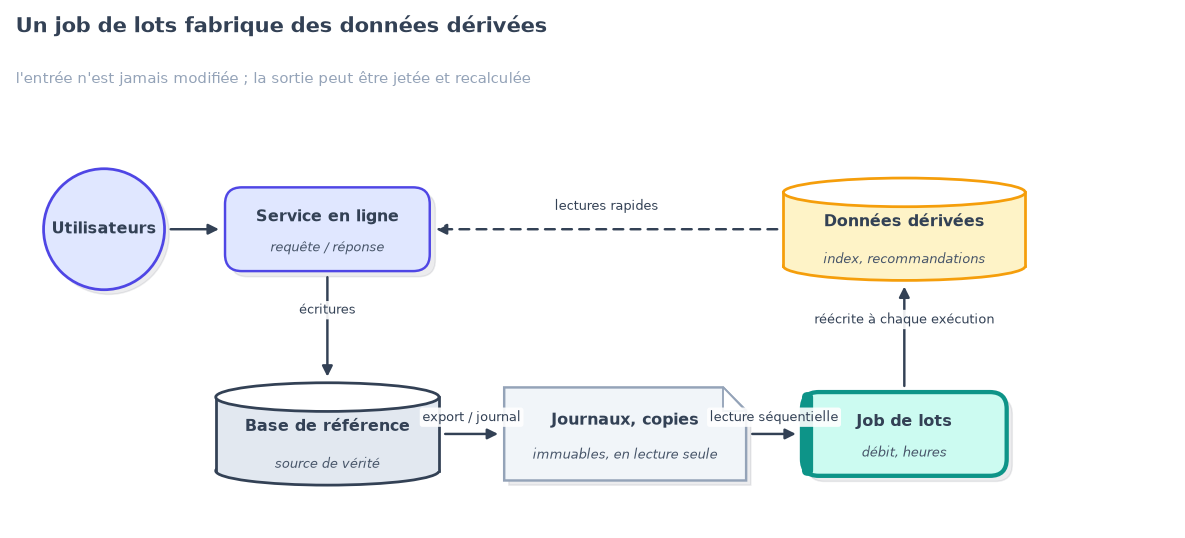

In [2]:
d = Diagram(12.5, 4.6, title="Un job de lots fabrique des données dérivées",
            subtitle="l'entrée n'est jamais modifiée ; la sortie peut être jetée et recalculée")
d.box("u", 1.0, 3.2, "Utilisateurs", kind="user", w=1.3, color=INDIGO)
d.box("app", 3.4, 3.2, "Service en ligne", sub="requête / réponse", color=INDIGO)
d.box("db", 3.4, 1.0, "Base de référence", sub="source de vérité", color=SLATE, kind="db", w=2.4, h=1.1)
d.box("logs", 6.6, 1.0, "Journaux, copies", sub="immuables, en lecture seule", color=GRAY, kind="doc", w=2.6, h=1.0)
d.box("job", 9.6, 1.0, "Job de lots", sub="débit, heures", color=TEAL, kind="model", w=2.2)
d.box("out", 9.6, 3.2, "Données dérivées", sub="index, recommandations", color=AMBER, kind="db", w=2.6, h=1.1)
d.arrow("u", "app", "")
d.arrow("app", "db", "écritures")
d.arrow("db", "logs", "export / journal")
d.arrow("logs", "job", "lecture séquentielle")
d.arrow("job", "out", "réécrite à chaque exécution")
d.arrow("out", "app", "lectures rapides", style="dashed", label_offset=(0, 0.25))
d.show()

**Pourquoi une entrée immuable change tout.** Si un job a un bogue, sa sortie est fausse,
mais l'entrée est intacte : on corrige le code et on relance, ou plus simplement on
rebascule sur la sortie de la veille, gardée dans un autre répertoire. Une base de
données modifiée en place par un code bogué, elle, garde les dégâts même après retour à
l'ancien code. Le livre parle de **tolérance aux fautes humaines** (*human fault
tolerance*). Le cours 5 y reviendra avec une démonstration.

Les ordres de grandeur ci-dessous (illustratifs) montrent ce qui sépare les trois mondes
: on n'optimise pas la même chose quand une réponse doit arriver en 10 ms et quand un job
a la nuit pour lire des téraoctets.

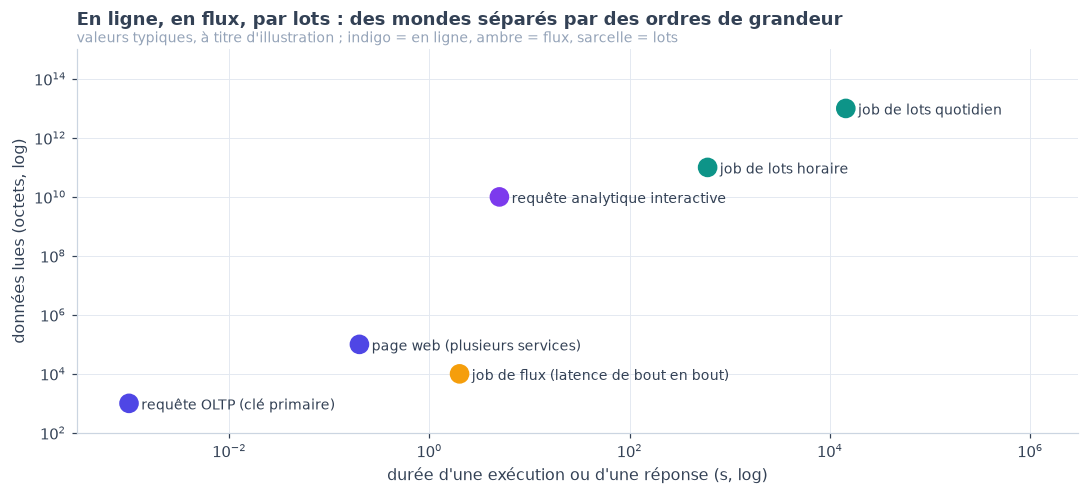

In [3]:
systemes = pd.DataFrame([
    ("requête OLTP (clé primaire)", 1e-3, 1e3, INDIGO),
    ("page web (plusieurs services)", 0.2, 1e5, INDIGO),
    ("requête analytique interactive", 5, 1e10, VIOLET),
    ("job de flux (latence de bout en bout)", 2, 1e4, AMBER),
    ("job de lots horaire", 600, 1e11, TEAL),
    ("job de lots quotidien", 4 * 3600, 1e13, TEAL),
], columns=["systeme", "duree_s", "octets", "couleur"])
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.scatter(systemes.duree_s, systemes.octets, s=140, c=systemes.couleur, zorder=3)
for _, r in systemes.iterrows():
    ax.annotate(r.systeme, (r.duree_s, r.octets), (8, -4), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(3e-4, 3e6); ax.set_ylim(1e2, 1e15)
ax.set_xlabel("durée d'une exécution ou d'une réponse (s, log)")
ax.set_ylabel("données lues (octets, log)")
ax.set_title("En ligne, en flux, par lots : des mondes séparés par des ordres de grandeur")
subtitle(ax, "valeurs typiques, à titre d'illustration ; indigo = en ligne, ambre = flux, sarcelle = lots")
plt.tight_layout(); plt.show()

> **À retenir.** Un job de lots lit une entrée **immuable** et produit une sortie
> **dérivée**, recalculée de zéro. On le juge à son débit, pas à son temps de réponse.
> Cette discipline permet de corriger une erreur en relançant le job, ce qu'une base
> modifiée en place ne permet pas.

## 2. Une analyse de journal avec les outils Unix (section *Simple Log Analysis*)

Un serveur web ajoute une ligne à son journal d'accès à chaque requête servie. Au format
« combined » de NGINX, une ligne contient l'adresse IP du client, l'utilisateur
authentifié (ou `-`), la date, la ligne de requête HTTP, le code de statut, la taille de
la réponse, la page d'origine (*referer*) et le navigateur (*user agent*). Faute de vrais
journaux, `B.generate_access_log` en fabrique : 400 000 requêtes sur 3 000 URL dont la
popularité suit une loi de Zipf (quelques pages très demandées, une longue traîne), comme
sur un vrai site.

In [4]:
lines = B.generate_access_log(400_000, n_urls=3000, s=1.1, seed=1)
LOG = os.path.join(WORK, "access.log")
taille = B.write_lines(LOG, lines)
print(f"{len(lines):,} lignes, {taille / 1e6:.0f} Mo".replace(",", " "))
print(lines[12])
champs = lines[12].split()
pd.DataFrame({"champ pour awk": [f"${i + 1}" for i in range(10)], "valeur": champs[:10]}).set_index("champ pour awk")

400 000 lignes  92 Mo
114.239.140.149 - - [15/Nov/2022:00:00:03 +0000] "GET /2022/05/15/schema-paxos-streams-curves.html HTTP/1.1" 200 32146 "https://example.org/" "Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:106.0) Gecko/20100101 Firefox/106.0"


,valeur
champ pour awk,
$1,114.239.140.149
$2,-
$3,-
$4,[15/Nov/2022:00:00:03
$5,+0000]
$6,"""GET"
$7,/2022/05/15/schema-paxos-streams-curves.html
$8,"HTTP/1.1"""
$9,200


Le septième champ séparé par des espaces (`$7` pour `awk`) est l'URL. Les cinq pages les
plus vues s'obtiennent par le pipeline que le livre présente :

```
cat access.log | awk '{print $7}' | sort | uniq -c | sort -r -n | head -n 5
```

`awk` extrait l'URL de chaque ligne ; `sort` range les URL par ordre alphabétique, ce qui
met côte à côte toutes les occurrences d'une même URL ; `uniq -c` remplace chaque série
de lignes identiques **adjacentes** par une seule ligne précédée de son nombre ; le second
`sort -r -n` classe par nombre décroissant, et `head` garde les cinq premières. Lançons
les vrais outils, puis regardons ce qui circule dans chaque tuyau.

In [5]:
top_unix, duree_unix = B.unix_top_k(LOG, 5)
print(f"pipeline Unix : {duree_unix:.2f} s")
for c, u in top_unix:
    print(f"{c:>7} {u}")

pipeline Unix : 0.13 s
  65714 /
  30692 /favicon.ico
  19648 /2014/10/19/shuffle-collaboration-streams.html
  14418 /2014/06/28/ethics-locking-streams.html
  11273 /2022/05/15/schema-paxos-streams-curves.html


In [6]:
etapes = {
    "awk '{print $7}'": f"awk '{{print $7}}' {LOG}",
    "| sort": f"awk '{{print $7}}' {LOG} | sort",
    "| uniq -c": f"awk '{{print $7}}' {LOG} | sort | uniq -c",
    "| sort -r -n": f"awk '{{print $7}}' {LOG} | sort | uniq -c | sort -r -n",
}
rows = []
for nom, cmd in etapes.items():
    out = sh(cmd).splitlines()
    rows.append({"étape": nom, "lignes en sortie": len(out), "3 premières lignes": " | ".join(x.strip() for x in out[:3])})
pd.DataFrame(rows)

,étape,lignes en sortie,3 premières lignes
0,awk '{print $7}',400000,/2021/12/04/first-crdt.html | /2017/12/11/logs-lsm-shuffle-schema.html | /
1,| sort,400000,/ | / | /
2,| uniq -c,3000,65714 / | 24 /2010/01/01/automerge-ethics-local-collaboration.html | 14 /2010/01/01/lo...
3,| sort -r -n,3000,65714 / | 30692 /favicon.ico | 19648 /2014/10/19/shuffle-collaboration-streams.html
